<a href="https://colab.research.google.com/github/udlbook/udlbook/blob/main/Notebooks/Chap09/9_4_Bayesian_Approach.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Increase Data

## Transfer Learning 

When training data are limited, other datasets can be exploited to improve performance.

<mark>In transfer learning (figure 9.12a), the network is pre-trained to perform a related secondary task for which data are more plentiful.</mark> 

The resulting model is then adapted to the original task. 

<mark>This is typically done by removing the last layer and adding one or more layers that produce a suitable output</mark>. 

The main model may be fixed, and the new layers trained for the original task, or we may fine-tune the entire model.

<mark>The principle is that the network will build a good internal representation of the data from the secondary task, which can subsequently be exploited for the original task</mark>.

Equivalently, <mark>transfer learning can be viewed as initializing most of the parameters of the final network in a sensible part of the space that is likely to produce a good solution</mark>.

<img src="assets/Chap09/RegTransferMulti.svg" width="100%" style="filter:invert(1)">

## Multi-task learning

Multi-task learning  is a related technique in which the network is trained to solve several problems concurrently. 

For example, the network might take an image and simultaneously learn to segment the scene, estimate the pixel-wise depth, and predict a caption describing the image. 

All of these tasks require some understanding of the image and, when learned simultaneously, the model performance for each may improve.


## Self-supervised learning

The above discussion assumes that we have plentiful data for a secondary task or data for multiple tasks to be learned concurrently. 

If not, we can create large amounts of “free” labeled data using self-supervised learning and use this for transfer learning. 

<mark>There are two families of methods for self-supervised learning: generative and contrastive</mark>.

<mark>In generative self-supervised learning, part of each data example is masked, and the
secondary task is to predict the missing part</mark>

For example, we might use a corpus of unlabeled images and a secondary task that aims to inpaint (fill in) missing
parts of the image (figure 9.12c). 

Similarly, we might use a large corpus of text and mask some words. 

We train the network to predict the missing words and then fine-tune it for the actual language task we are interested in (see chapter 12).

<mark>In contrastive self-supervised learning, pairs of examples with commonalities are compared to unrelated pairs</mark>. 

For images, the secondary task might be to identify whether a pair of images are transformed versions of one another or are unconnected. 

For text, the secondary task might be to determine whether two sentences followed one another in the original document. Sometimes, the precise relationship between a connected pair must be identified (e.g., finding the relative position of two patches from the same image).

## Augmentation

Transfer learning improves performance by exploiting a different dataset. 

Multi-task learning improves performance using additional labels. 

A third option is to expand the dataset. 

<mark>We can often transform each input data example in such a way that the label stays the same. 

For example, we might aim to determine if there is a bird in an image. Here, we could rotate, flip, blur, or manipulate the color balance of the image, and the label “bird” remains valid. 

Similarly, for tasks where the input is text, we can substitute synonyms or translate to another language and back again. 

For tasks where the input is audio, we can amplify or attenuate different frequency bands.</mark>

<img src="assets/Chap09/RegAugment.svg" width="100%" style="filter:invert(0)">

Data augmentation. For some problems, each data example can be
transformed to augment the dataset. a) Original image. b–h) Various geometric
and photometric transformations of this image. For image classification, all these
images still have the same label, “bird.” Adapted from Wu et al. (2015a).

---

Generating extra training data in this way is known as data augmentation. The aim
is to teach the model to be indifferent to these irrelevant data transformations.

In [ ]:
# Run this if you're in a Colab to install MNIST 1D repository
!pip install git+https://github.com/greydanus/mnist1d

In [13]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import StepLR
import numpy as np
import matplotlib.pyplot as plt
import mnist1d
import random

plt.style.use('dark_background')

In [14]:
args = mnist1d.data.get_dataset_args()
data = mnist1d.data.get_dataset(args, path='./mnist1d_data.pkl', download=False, regenerate=False)

# The training and test input and outputs are in
# data['x'], data['y'], data['x_test'], and data['y_test']
print("Examples in training set: {}".format(len(data['y'])))
print("Examples in test set: {}".format(len(data['y_test'])))
print("Length of each example: {}".format(data['x'].shape[-1]))

Successfully loaded data from ./mnist1d_data.pkl
Examples in training set: 4000
Examples in test set: 4000
Length of each example: 40


In [15]:
D_i = 40    # Input dimensions
D_k = 200   # Hidden dimensions
D_o = 10    # Output dimensions

# Define a model with two hidden layers of size 200
# And ReLU activations between them
model = nn.Sequential(
nn.Linear(D_i, D_k),
nn.ReLU(),
nn.Linear(D_k, D_k),
nn.ReLU(),
nn.Linear(D_k, D_o))

def weights_init(layer_in):
  # Initialize the parameters with He initialization
  if isinstance(layer_in, nn.Linear):
    nn.init.kaiming_uniform_(layer_in.weight)
    layer_in.bias.data.fill_(0.0)


In [16]:
# choose cross entropy loss function (equation 5.24)
loss_function = torch.nn.CrossEntropyLoss()
# construct SGD optimizer and initialize learning rate and momentum
optimizer = torch.optim.SGD(model.parameters(), lr = 0.05, momentum=0.9)
# object that decreases learning rate by half every 10 epochs
scheduler = StepLR(optimizer, step_size=10, gamma=0.5)
# create 100 dummy data points and store in data loader class
x_train = torch.tensor(data['x'].astype('float32'))
y_train = torch.tensor(data['y'].transpose().astype('long'))
x_test= torch.tensor(data['x_test'].astype('float32'))
y_test = torch.tensor(data['y_test'].astype('long'))

# load the data into a class that creates the batches
data_loader = DataLoader(TensorDataset(x_train,y_train), batch_size=100, shuffle=True, worker_init_fn=np.random.seed(1))

# Initialize model weights
model.apply(weights_init)

# loop over the dataset n_epoch times
n_epoch = 50
# store the loss and the % correct at each epoch
errors_train = np.zeros((n_epoch))
errors_test = np.zeros((n_epoch))

for epoch in range(n_epoch):
  # loop over batches
  for i, batch in enumerate(data_loader):
    # retrieve inputs and labels for this batch
    x_batch, y_batch = batch
    # zero the parameter gradients
    optimizer.zero_grad()
    # forward pass -- calculate model output
    pred = model(x_batch)
    # compute the loss
    loss = loss_function(pred, y_batch)
    # backward pass
    loss.backward()
    # SGD update
    optimizer.step()

  # Run whole dataset to get statistics -- normally wouldn't do this
  pred_train = model(x_train)
  pred_test = model(x_test)
  _, predicted_train_class = torch.max(pred_train.data, 1)
  _, predicted_test_class = torch.max(pred_test.data, 1)
  errors_train[epoch] = 100 - 100 * (predicted_train_class == y_train).float().sum() / len(y_train)
  errors_test[epoch]= 100 - 100 * (predicted_test_class == y_test).float().sum() / len(y_test)
  print(f'Epoch {epoch:5d}, train error {errors_train[epoch]:3.2f}, test error {errors_test[epoch]:3.2f}')

Epoch     0, train error 57.78, test error 64.18
Epoch     1, train error 44.42, test error 54.05
Epoch     2, train error 33.00, test error 47.65
Epoch     3, train error 28.35, test error 43.65
Epoch     4, train error 21.85, test error 42.05
Epoch     5, train error 19.70, test error 40.15
Epoch     6, train error 15.10, test error 39.35
Epoch     7, train error 12.20, test error 40.12
Epoch     8, train error 7.80, test error 38.00
Epoch     9, train error 9.20, test error 38.10
Epoch    10, train error 4.20, test error 36.53
Epoch    11, train error 3.38, test error 38.35
Epoch    12, train error 1.93, test error 36.28
Epoch    13, train error 1.05, test error 35.70
Epoch    14, train error 0.53, test error 35.82
Epoch    15, train error 0.03, test error 35.32
Epoch    16, train error 0.03, test error 35.43
Epoch    17, train error 0.03, test error 34.65
Epoch    18, train error 0.00, test error 34.97
Epoch    19, train error 0.00, test error 34.72
Epoch    20, train error 0.00, t

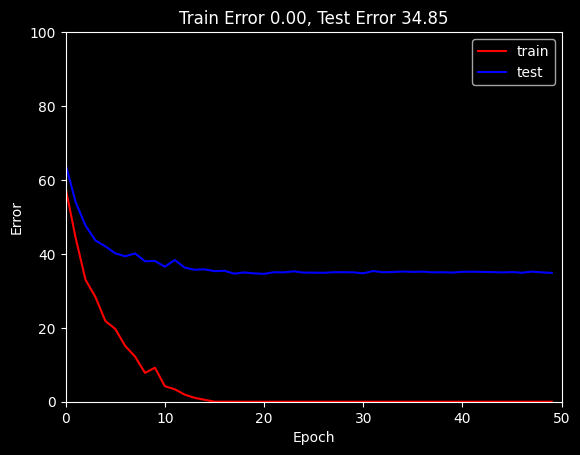

In [17]:
# Plot the results
fig, ax = plt.subplots()
ax.plot(errors_train,'r-',label='train')
ax.plot(errors_test,'b-',label='test')
ax.set_ylim(0,100); ax.set_xlim(0,n_epoch)
ax.set_xlabel('Epoch'); ax.set_ylabel('Error')
ax.set_title('Train Error %3.2f, Test Error %3.2f'%(errors_train[-1],errors_test[-1]))
ax.legend()
plt.show()

The best test performance is about 33%.  Let's see if we can improve on that by augmenting the data.

In [18]:
def augment(input_vector):
  # Create output vector
  data_out = np.zeros_like(input_vector)

  data_out = np.roll(input_vector, np.random.randint(len(input_vector)))

  data_out = data_out * np.random.uniform(0.8, 1.2)

  return data_out

In [19]:
n_data_orig = data['x'].shape[0]
# We'll double the amount of data
n_data_augment = n_data_orig+4000
augmented_x = np.zeros((n_data_augment, D_i))
augmented_y = np.zeros(n_data_augment)
# First n_data_orig rows are original data
augmented_x[0:n_data_orig,:] = data['x']
augmented_y[0:n_data_orig] = data['y']

# Fill in rest of with augmented data
for c_augment in range(n_data_orig, n_data_augment):
  # Choose a data point randomly
  random_data_index = random.randint(0, n_data_orig-1)
  # Augment the point and store
  augmented_x[c_augment,:] = augment(data['x'][random_data_index,:])
  augmented_y[c_augment] = data['y'][random_data_index]


In [20]:
# choose cross entropy loss function (equation 5.24)
loss_function = torch.nn.CrossEntropyLoss()
# construct SGD optimizer and initialize learning rate and momentum
optimizer = torch.optim.SGD(model.parameters(), lr = 0.05, momentum=0.9)
# object that decreases learning rate by half every 50 epochs
scheduler = StepLR(optimizer, step_size=10, gamma=0.5)
# create 100 dummy data points and store in data loader class
x_train = torch.tensor(augmented_x.astype('float32'))
y_train = torch.tensor(augmented_y.transpose().astype('long'))
x_test= torch.tensor(data['x_test'].astype('float32'))
y_test = torch.tensor(data['y_test'].astype('long'))

# load the data into a class that creates the batches
data_loader = DataLoader(TensorDataset(x_train,y_train), batch_size=100, shuffle=True, worker_init_fn=np.random.seed(1))

# Initialize model weights
model.apply(weights_init)

# loop over the dataset n_epoch times
n_epoch = 50
# store the loss and the % correct at each epoch
errors_train_aug = np.zeros((n_epoch))
errors_test_aug = np.zeros((n_epoch))

for epoch in range(n_epoch):
  # loop over batches
  for i, batch in enumerate(data_loader):
    # retrieve inputs and labels for this batch
    x_batch, y_batch = batch
    # zero the parameter gradients
    optimizer.zero_grad()
    # forward pass -- calculate model output
    pred = model(x_batch)
    # compute the loss
    loss = loss_function(pred, y_batch)
    # backward pass
    loss.backward()
    # SGD update
    optimizer.step()

  # Run whole dataset to get statistics -- normally wouldn't do this
  pred_train = model(x_train)
  pred_test = model(x_test)
  _, predicted_train_class = torch.max(pred_train.data, 1)
  _, predicted_test_class = torch.max(pred_test.data, 1)
  errors_train_aug[epoch] = 100 - 100 * (predicted_train_class == y_train).float().sum() / len(y_train)
  errors_test_aug[epoch]= 100 - 100 * (predicted_test_class == y_test).float().sum() / len(y_test)
  print(f'Epoch {epoch:5d}, train error {errors_train_aug[epoch]:3.2f}, test error {errors_test_aug[epoch]:3.2f}')

Epoch     0, train error 56.17, test error 58.08
Epoch     1, train error 46.33, test error 50.03
Epoch     2, train error 37.89, test error 46.03
Epoch     3, train error 34.11, test error 43.05
Epoch     4, train error 28.26, test error 40.47
Epoch     5, train error 24.22, test error 38.85
Epoch     6, train error 20.88, test error 37.67
Epoch     7, train error 16.61, test error 35.95
Epoch     8, train error 16.49, test error 37.05
Epoch     9, train error 14.16, test error 36.67
Epoch    10, train error 10.54, test error 36.80
Epoch    11, train error 8.03, test error 33.68
Epoch    12, train error 7.65, test error 35.15
Epoch    13, train error 9.35, test error 37.40
Epoch    14, train error 5.47, test error 34.57
Epoch    15, train error 3.89, test error 34.00
Epoch    16, train error 3.45, test error 34.30
Epoch    17, train error 2.25, test error 33.68
Epoch    18, train error 1.56, test error 33.35
Epoch    19, train error 0.32, test error 32.90
Epoch    20, train error 0.06

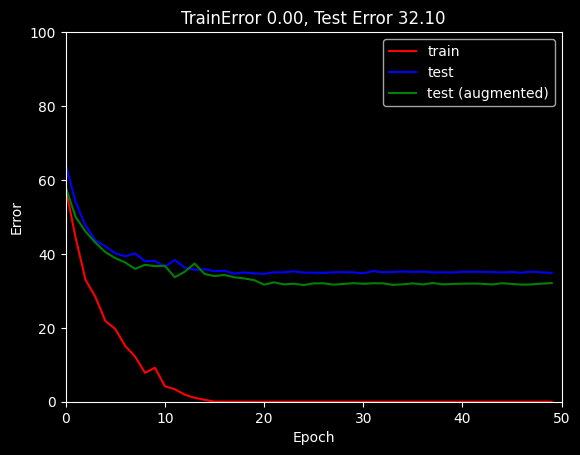

In [21]:
# Plot the results
fig, ax = plt.subplots()
ax.plot(errors_train,'r-',label='train')
ax.plot(errors_test,'b-',label='test')
ax.plot(errors_test_aug,'g-',label='test (augmented)')
ax.set_ylim(0,100); ax.set_xlim(0,n_epoch)
ax.set_xlabel('Epoch'); ax.set_ylabel('Error')
ax.set_title('TrainError %3.2f, Test Error %3.2f'%(errors_train_aug[-1],errors_test_aug[-1]))
ax.legend()
plt.show()